# 14. Stacking (5 bases)

Five different base models (logistic regression, averaged perceptron, Naive Bayes, linear SVC, k-NN) make
out-of-fold predictions with 5-fold CV on the train set; a logistic-regression meta-model learns how much to
trust each of them.

From-scratch code: `ClassificationAlgorithms/Stackingclassifier.py` · charts: `Images/Classification/14_Stacking/` · tables: `Results/Classification/14_Stacking/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

import numpy as np
from project import SEED, Outputs, classification_data
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from Stackingclassifier import StackingClassifierScratch, default_base_models
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

out = Outputs("Classification", "14_Stacking")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it (validation set = early stopping)
model = StackingClassifierScratch(default_base_models(SEED), n_folds=5, random_state=SEED)
check_settings("Stacking (5 bases)", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification: scikit-learn StackingClassifier with comparable bases
sc = StandardScaler().fit(d.X_tr)
sk = StackingClassifier(
    [("lr", LogisticRegression(max_iter=2000)), ("nb", GaussianNB()), ("knn", KNeighborsClassifier(25))],
    final_estimator=LogisticRegression(),
    cv=3,
    n_jobs=-1,
).fit(sc.transform(d.X_tr), d.y_tr)
check = sklearn_check(
    "Stacking vs sklearn StackingClassifier",
    np.nan,
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, sk.predict_proba(sc.transform(d.X_te))[:, 1]),
    "AUC only",
)

settings match Common/model_zoo.py (7 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.1148        0.5000
log loss                            0.4078           NaN
accuracy                            0.4530        0.8403
precision                           0.2072        0.4444
recall / sensitivity                0.8623        0.0131
specificity                         0.3755           NaN
F1                                  0.3342        0.0255
ROC-AUC                             0.7025           NaN
PR-AUC                              0.2944           NaN
defaulters missed (FN)             42.0000           NaN

catches 86.2% of the 305 test defaulters (42 missed), flags 66.2% of applicants


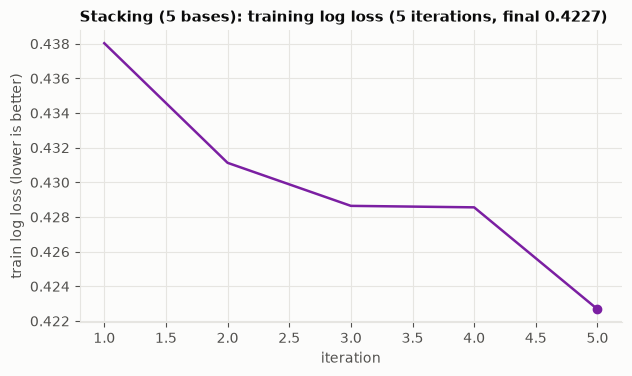

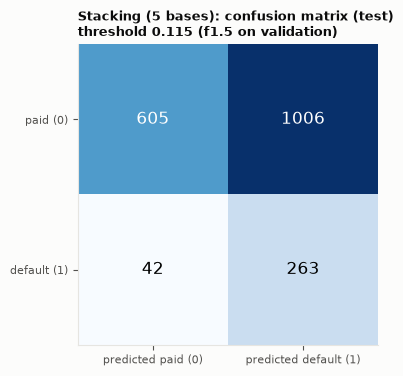

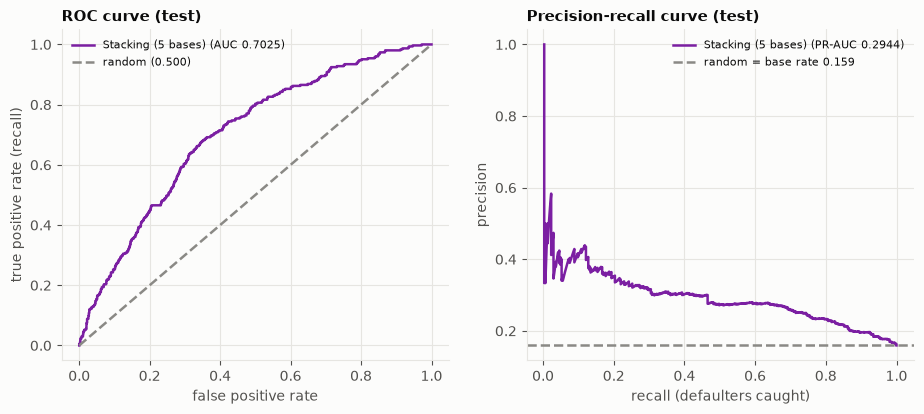


scratch vs library:
  Stacking vs sklearn StackingClassifier
    AUC scratch 0.7025 | AUC library 0.7025 | AUC only = nan



saved + reloaded TrainedModels/Classification/14_Stacking.joblib (identical predictions: True)


In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "Stacking (5 bases)", model, d, check)